# Dar_053 - Seismic: all motion axes, instrument modes, response experiments and time

## Questions
- What do horizontal MH1/MH2 add to vertical MHZ across the full selected 1973-1974 history?
- How do native missing codes, mode/axis, metadata response and ATT timing affect interpretation?
- How sensitive are selected gap-free inverse-response experiments to explicitly declared diagnostic prefilters?
- Do month, quarter, four-month term, half-year, year, two-year and calendar-season groupings preserve support and the old vertical summaries?
- What is still missing for local structural/hazard requirements?

All selected S12 motion files are read. The earlier complete ATT diagnostics are reused with provenance, not misclassified as a fourth motion axis. Raw counts are not acceleration; metadata-based displacement experiments are not qualified event peaks or structural demand. Natural/crew/rover/deliberate-source attribution and local south-polar recurrence remain unresolved. Calendar seasons are labels only.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'env_algo_task/EDA').is_dir())
sys.path.insert(0,str(root/'env_algo_task/EDA/Moon/Stage3_Requirements'))
from stage3_seismic_eda import execute

## Execute the complete selected motion cohort
A separate first/last-file sample per axis/location mode precedes this full execution. Raw data/labels and StationXML are receipt/hash checked; all previous ATT diagnostics remain a distinct input.

In [2]:
folder,findings=execute(sample=False)
display(findings)

Motion files read: 1


Motion files read: 201


Motion files read: 401


Motion files read: 601


Motion files read: 801


Motion files read: 1001


... (3 outputs left out)

Motion files read: 1801


Motion files read: 2001


{
  "subject": "seismic",
  "sample": false,
  "analysed_motion_files": 2193,
  "motion_traces": 2193,
  "native_motion_samples": 1246454631,
  "valid_native_motion_samples": 1220986653,
  "motion_axes": [
    "MH1",
    "MH2",
    "MHZ"
  ],
  "archived_ATT_traces_reused": 730,
  "response_experiment_rows": 300,
  "tables": {
    "raw_trace_support": 2193,
    "response_metadata": 2193,
    "response_experiments": 300,
    "selected_window_raw_PSD": 153750,
    "daily_context": 2193,
    "archived_ATT_context": 730,
    "calendar_context": 241,
    "matched_January_December_years": 11,
    "crosscheck_Dar044": 6,
    "stage4_seismic_proposals": 5
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar labels only, not lunar seasons",
  "base_conclusion": "Three-axis/mode/clock support and bounded inverse-response experiments improve historical waveform interpre

{'subject': 'seismic',
 'sample': False,
 'analysed_motion_files': 2193,
 'motion_traces': 2193,
 'native_motion_samples': 1246454631,
 'valid_native_motion_samples': 1220986653,
 'motion_axes': ['MH1', 'MH2', 'MHZ'],
 'archived_ATT_traces_reused': 730,
 'response_experiment_rows': 300,
 'tables': {'raw_trace_support': 2193,
  'response_metadata': 2193,
  'response_experiments': 300,
  'selected_window_raw_PSD': 153750,
  'daily_context': 2193,
  'archived_ATT_context': 730,
  'calendar_context': 241,
  'matched_January_December_years': 11,
  'crosscheck_Dar044': 6,
  'stage4_seismic_proposals': 5},
 'time_contract': 'UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar labels only, not lunar seasons',
 'base_conclusion': 'Three-axis/mode/clock support and bounded inverse-response experiments improve historical waveform interpretation. They do not establish independent natural events

## Axes, modes and native/clock support
The shared daily-value column contains median-centred **whole-file RMS counts**, not a native median or corrected displacement. No qualified elapsed-time coverage is invented. Peak/broadband mode comments, epochs, orientation and metadata clock drift remain explicit.

,axis,location_mode_code,mode_comment,azimuth_deg,dip_deg,response_input_unit,response_status
0,MH1,0,Peak Mode,180.0,0.0,M,Available_same_epoch
1,MH2,0,Peak Mode,270.0,0.0,M,Available_same_epoch
2,MHZ,0,Peak Mode,0.0,-90.0,M,Available_same_epoch
1962,MH1,1,Broadband Mode,180.0,0.0,M,Available_same_epoch
1963,MH2,1,Broadband Mode,270.0,0.0,M,Available_same_epoch
1964,MHZ,1,Broadband Mode,0.0,-90.0,M,Available_same_epoch


,file,trace_id,start,stop,samples,valid_samples,sampling_rate_Hz,missing_code,scope,quantity,nonpositive_steps,median_positive_step_s,maximum_positive_step_s,response_at_both_ends,raw_median,demeaned_rms_counts,p95_absolute_deviation_counts,date
0,xa.s12..att.1973.001.0.mseed,XA.S12..ATT,1973-01-01T00:00:08.329979Z,1973-01-01T23:59:59.273375Z,143086,142933,1.65625,-1,nominal archive timing; no event detection or ...,timing,0.0,0.604,0.614,NaN,NaN,NaN,NaN,1973-01-01 00:00:00+00:00
1,xa.s12..att.1973.002.0.mseed,XA.S12..ATT,1973-01-02T00:00:00.035000Z,1973-01-02T23:59:59.431226Z,143100,142953,1.65625,-1,nominal archive timing; no event detection or ...,timing,0.0,0.604,0.614,NaN,NaN,NaN,NaN,1973-01-02 00:00:00+00:00
2,xa.s12..att.1973.003.0.mseed,XA.S12..ATT,1973-01-03T00:00:00.216000Z,1973-01-03T23:59:59.612226Z,143100,143097,1.65625,-1,nominal archive timing; no event detection or ...,timing,0.0,0.604,0.614,NaN,NaN,NaN,NaN,1973-01-03 00:00:00+00:00
3,xa.s12..att.1973.004.0.mseed,XA.S12..ATT,1973-01-04T00:00:00.414000Z,1973-01-04T23:59:59.206453Z,143099,142905,1.65625,-1,nominal archive timing; no event detection or ...,timing,0.0,0.604,0.614,NaN,NaN,NaN,NaN,1973-01-04 00:00:00+00:00
4,xa.s12..att.1973.005.0.mseed,XA.S12..ATT,1973-01-05T00:00:00.028000Z,1973-01-05T23:59:59.424226Z,143100,143093,1.65625,-1,nominal archive timing; no event detection or ...,timing,0.0,0.604,0.612,NaN,NaN,NaN,NaN,1973-01-05 00:00:00+00:00


period_kind
calendar_season    39
four_month_term    27
half_year          19
month              99
quarter            35
two_year           11
year               11
Name: rows, dtype: int64

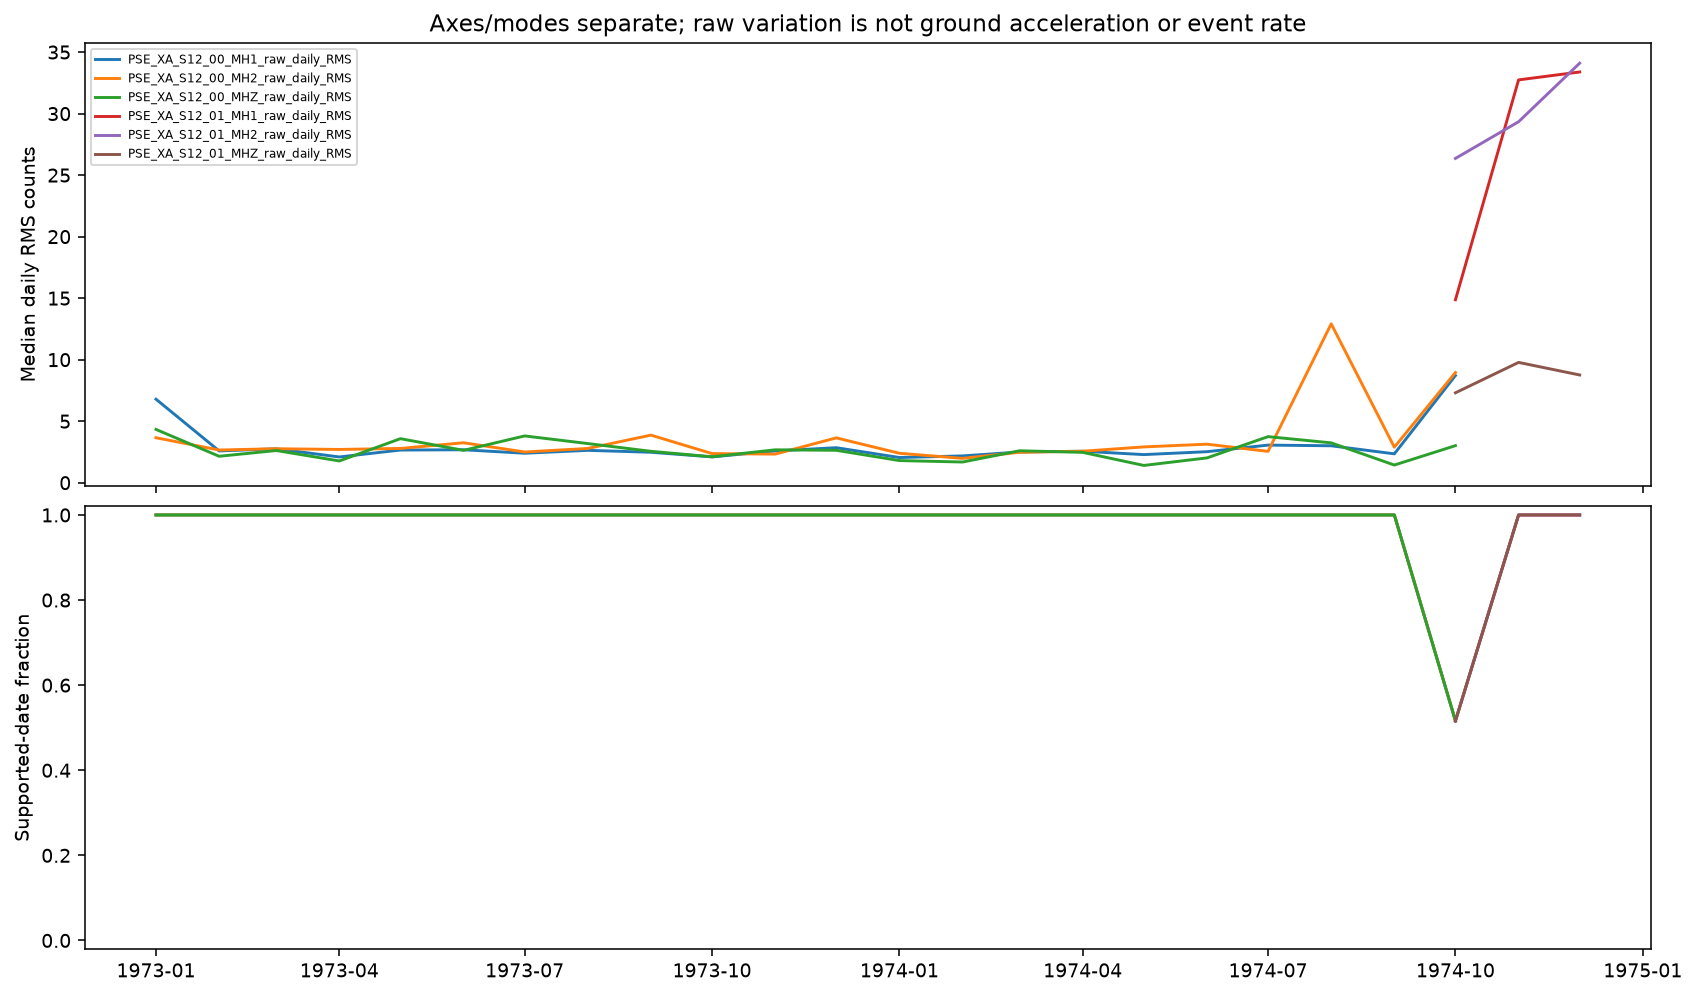

In [3]:
display(pd.read_csv(folder/'response_metadata.csv').drop_duplicates(['axis','location_mode_code','mode_comment'])[['axis','location_mode_code','mode_comment','azimuth_deg','dip_deg','response_input_unit','response_status']])
display(pd.read_csv(folder/'archived_ATT_context.csv').head())
display(pd.read_csv(folder/'calendar_context.csv').groupby('period_kind').size().rename('rows'))
display(Image(filename=str(folder/'raw_axes_calendar.png')))

## Bounded inverse-response experiments
Select first/last archive file per axis/mode/month before values are examined, then the first fully valid 8,192-sample segment. Two prefilter choices, 60 dB water level and 5% taper are **analysis sensitivity settings, not NASA limits**. Instrument sensitivity alone is not used as a broadband counts-to-metres conversion. Actual inverse response is applied; nominal archive timing and window/event selection remain limitations.

,file,trace_id,date,axis,location_mode_code,experiment_status,filter_choice,prefilter_Hz,water_level_dB,taper_fraction,window_samples,window_first_native_index,window_start_nominal_utc,window_stop_nominal_utc,displacement_rms_m,maximum_absolute_displacement_m,interpretation
0,xa.s12.00.mh1.1973.001.0.mseed,XA.S12.00.MH1,1973-01-01 00:00:00+00:00,MH1,0,Available_exploratory_only,wider_diagnostic_band,"[0.02, 0.03, 1.0, 1.5]",60,0.05,8192,0,1973-01-01T00:00:08.404979Z,1973-01-01T00:20:44.782337Z,4.126655e-09,1.526740e-08,band-limited metadata-based displacement exper...
1,xa.s12.00.mh1.1973.001.0.mseed,XA.S12.00.MH1,1973-01-01 00:00:00+00:00,MH1,0,Available_exploratory_only,narrower_diagnostic_band,"[0.05, 0.08, 0.6, 1.0]",60,0.05,8192,0,1973-01-01T00:00:08.404979Z,1973-01-01T00:20:44.782337Z,7.082230e-10,3.332065e-09,band-limited metadata-based displacement exper...
2,xa.s12.00.mh2.1973.001.0.mseed,XA.S12.00.MH2,1973-01-01 00:00:00+00:00,MH2,0,Available_exploratory_only,wider_diagnostic_band,"[0.02, 0.03, 1.0, 1.5]",60,0.05,8192,0,1973-01-01T00:00:08.423979Z,1973-01-01T00:20:44.801337Z,2.509469e-09,8.635081e-09,band-limited metadata-based displacement exper...
3,xa.s12.00.mh2.1973.001.0.mseed,XA.S12.00.MH2,1973-01-01 00:00:00+00:00,MH2,0,Available_exploratory_only,narrower_diagnostic_band,"[0.05, 0.08, 0.6, 1.0]",60,0.05,8192,0,1973-01-01T00:00:08.423979Z,1973-01-01T00:20:44.801337Z,4.872077e-10,1.567627e-09,band-limited metadata-based displacement exper...
4,xa.s12.00.mhz.1973.001.0.mseed,XA.S12.00.MHZ,1973-01-01 00:00:00+00:00,MHZ,0,Available_exploratory_only,wider_diagnostic_band,"[0.02, 0.03, 1.0, 1.5]",60,0.05,8192,0,1973-01-01T00:00:08.442979Z,1973-01-01T00:20:44.820337Z,2.038753e-09,5.460007e-09,band-limited metadata-based displacement exper...
5,xa.s12.00.mhz.1973.001.0.mseed,XA.S12.00.MHZ,1973-01-01 00:00:00+00:00,MHZ,0,Available_exploratory_only,narrower_diagnostic_band,"[0.05, 0.08, 0.6, 1.0]",60,0.05,8192,0,1973-01-01T00:00:08.442979Z,1973-01-01T00:20:44.820337Z,4.775488e-10,1.798570e-09,band-limited metadata-based displacement exper...
6,xa.s12.00.mh1.1973.031.0.mseed,XA.S12.00.MH1,1973-01-31 00:00:00+00:00,MH1,0,Available_exploratory_only,wider_diagnostic_band,"[0.02, 0.03, 1.0, 1.5]",60,0.05,8192,0,1973-01-31T00:00:00.557000Z,1973-01-31T00:20:36.934358Z,2.757131e-09,9.630527e-09,band-limited metadata-based displacement exper...
7,xa.s12.00.mh1.1973.031.0.mseed,XA.S12.00.MH1,1973-01-31 00:00:00+00:00,MH1,0,Available_exploratory_only,narrower_diagnostic_band,"[0.05, 0.08, 0.6, 1.0]",60,0.05,8192,0,1973-01-31T00:00:00.557000Z,1973-01-31T00:20:36.934358Z,5.723219e-10,2.138467e-09,band-limited metadata-based displacement exper...
8,xa.s12.00.mh2.1973.031.0.mseed,XA.S12.00.MH2,1973-01-31 00:00:00+00:00,MH2,0,Available_exploratory_only,wider_diagnostic_band,"[0.02, 0.03, 1.0, 1.5]",60,0.05,8192,0,1973-01-31T00:00:00.576000Z,1973-01-31T00:20:36.953358Z,2.448392e-09,1.157176e-08,band-limited metadata-based displacement exper...
9,xa.s12.00.mh2.1973.031.0.mseed,XA.S12.00.MH2,1973-01-31 00:00:00+00:00,MH2,0,Available_exploratory_only,narrower_diagnostic_band,"[0.05, 0.08, 0.6, 1.0]",60,0.05,8192,0,1973-01-31T00:00:00.576000Z,1973-01-31T00:20:36.953358Z,3.721454e-10,1.686983e-09,band-limited metadata-based displacement exper...


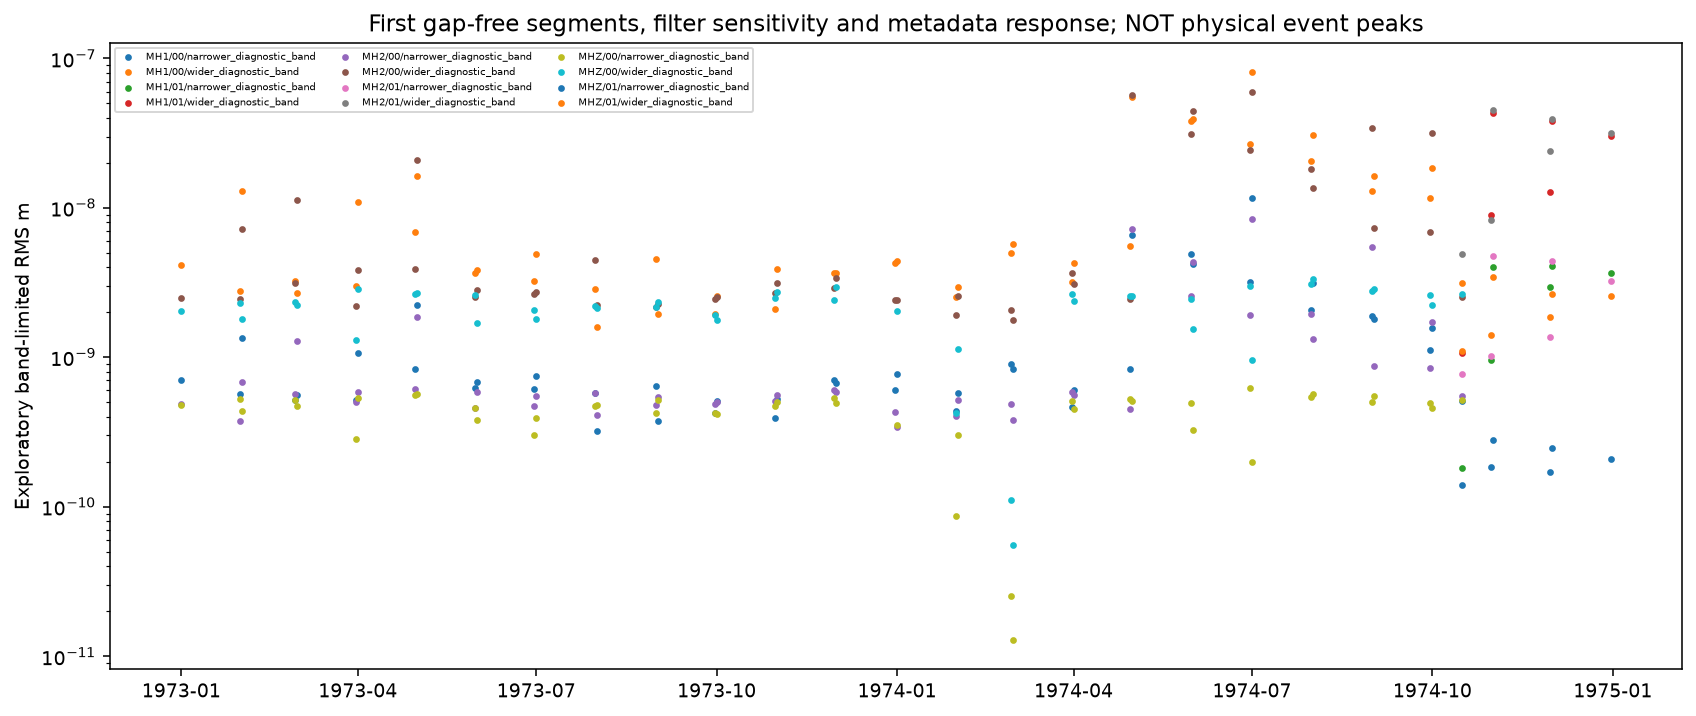

In [4]:
display(pd.read_csv(folder/'response_experiments.csv').head(20))
display(Image(filename=str(folder/'bounded_response_experiments.png')))

## Cross-check and Stage 4 proposals
All original vertical trace statistics must replay. Raw axes and selected response experiments do not identify independent natural events, local recurrence, guaranteed motion peaks or qualified structure response. Conditional mandatory tolerance checks require those missing inputs; no pipeline integration occurs.

In [5]:
display(pd.read_csv(folder/'crosscheck_Dar044.csv'))
display(pd.read_csv(folder/'stage4_seismic_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

,quantity,old_rows,matched_rows,support_changed_rows,maximum_absolute_difference,scope
0,samples,731,731,0,0.000000e+00,all prior vertical traces must replay identica...
1,valid_samples,731,731,0,0.000000e+00,all prior vertical traces must replay identica...
2,sampling_rate_Hz,731,731,0,0.000000e+00,all prior vertical traces must replay identica...
3,raw_median,731,731,0,0.000000e+00,all prior vertical traces must replay identica...
4,demeaned_rms_counts,731,731,0,7.105427e-15,all prior vertical traces must replay identica...
5,p95_absolute_deviation_counts,731,731,0,0.000000e+00,all prior vertical traces must replay identica...


,id,classification,title,current_outcome,decision_logic
0,SE-G01,evidence_guard,"Preserve axes, mode, response epoch and clocks",Unknown,Raw counts are not acceleration; metadata avai...
1,SE-G02,evidence_guard,Spectral/response experiments are bounded and ...,Unknown,First/last archive days and first gap-free seg...
2,SE-H01,conditional_hard_constraint,Applicable structural/vibration/impact tolerance,Unknown,Failed if qualified applicable demand exceeds ...
3,SE-S01,conditional_soft_preference,Lower qualified vibration/isolation operating ...,Unknown,"No lowest raw RMS, quiet archive window or spa..."
4,SE-G03,evidence_guard,Natural versus operational events and geograph...,Unknown,Related catalogs are not independent populatio...


{
  "subject": "seismic",
  "sample": false,
  "analysed_motion_files": 2193,
  "motion_traces": 2193,
  "native_motion_samples": 1246454631,
  "valid_native_motion_samples": 1220986653,
  "motion_axes": [
    "MH1",
    "MH2",
    "MHZ"
  ],
  "archived_ATT_traces_reused": 730,
  "response_experiment_rows": 300,
  "tables": {
    "raw_trace_support": 2193,
    "response_metadata": 2193,
    "response_experiments": 300,
    "selected_window_raw_PSD": 153750,
    "daily_context": 2193,
    "archived_ATT_context": 730,
    "calendar_context": 241,
    "matched_January_December_years": 11,
    "crosscheck_Dar044": 6,
    "stage4_seismic_proposals": 5
  },
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; DJF/MAM/JJA/SON are calendar labels only, not lunar seasons",
  "base_conclusion": "Three-axis/mode/clock support and bounded inverse-response experiments improve historical waveform interpre